In [1]:
NAMES = ['Angela DiAndreth', 'Sergey Dutt', 'Edward Lombo-Becerra']

In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import scipy.signal as signal
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

np.random.seed(42)  # for reproducibility

In [3]:
from fix_data import get_random_subset, load_and_center_data

# Project Title: Finding an Unbiased Pendulum Model for Parameter-Estimation Simulations

# Introduction:

Many common engineering components move according to simple harmonic motion (pendulums, springs, strings, and wires). When designing systems with these parts, you often need their oscillations to decay at a specific rate. To aid in hardware sizing, you can input this desired decay target into a parameter simulation, which directly outputs physical specifications like length and mass.

Here is an example problem: Consider an inertia-driven semi-automatic shotgun used in trap and skeet competitions. In this system, the bolt body acts as a floating mass (m), and an inertia spring of length L sits compressed between the bolt body and the bolt carrier. Firing a standard 12-gauge shell imparts an average force of 1,250N into the spring, pushing the bolt carrier backward to unlock the action, eject the spent shell, and chamber a new round.
To achieve a target fire rate of 4 rounds per second (240RPM) without jamming or misfiring, the spring’s oscillation must decay by $99\%$ before the next shot. Based on this fire rate and safety margin, the spring requires a decay constant of at least 36.84s-1. Additionally, the inertia spring can be no longer than 8cm and the bolt no heavier than 500g. The simulation must determine the optimal spring length ($L$), bolt mass ($m$), and spring stiffness ($k$) to meet these goals.

For this simulation to work, the math model must rely on unbiased physical parameters. This means any uncertainty in a parameter like length ($L$) must come purely from random noise, rather than absorbing the unaccounted physics of another variable. The goal of this project is to use experimental pendulum data to calibrate a simple harmonic model that accurately tracks trajectory data while keeping its physical parameters completely unbiased. If we are successful in finding a model that matches both criteria, we may attempt the example problem from the previous paragraph.


The differential equation for simple harmonic motion takes the standard form:

$$
\ddot{x} + a_1 \dot{x} + a_2 x = 0
$$

with the analytical solution:

$$
x(t) = e^{-\alpha t} \left( A \cos(\beta t) + B \sin(\beta t) \right)
$$

This following is how the differential equation for a pendulum decaying due to linear air resistance takes the form of simple harmonic motion. Beginning with the Euler-Lagrange equation derived from Hamilton's Principle of Least Action in classical mechanics:

$$
\frac{d}{dt} \left( \frac{\partial \mathcal{L}}{\partial \dot{q}_j} \right) - \frac{\partial \mathcal{L}}{\partial q_j} = 0
$$

The Lagrangian ($\mathcal{L}$) represents the total kinetic energy ($T$) minus the total potential energy ($U$) of the system:
$$
\mathcal{L} = T - U
$$

In Cartesian coordinates, $T = \frac{1}{2} m v^2$ and $U = mgh$. For a pendulum, its height relative to its lowest point is $h = L(1 - \cos\theta)$, where $\theta$ is the angular displacement from equilibrium. Similarly, its linear velocity $v$ is the time derivative of its arc length $s = L \theta$, yielding $v = L \dot{\theta}$.

Plugging these into the Lagrangian yields:

$$
\mathcal{L} = \frac{1}{2} m L^2 \dot{\theta}^2 + mgL(1 - \cos\theta)
$$

However, the conservative Lagrangian formulation only accounts for restorative forces and neglects energy loss. To model the motion of our decaying pendulum, we introduce non-conservative dissipation by replacing the right-hand side of the Euler-Lagrange equation with a linear Rayleigh drag force:

$$
\frac{d}{dt} \left( \frac{\partial \mathcal{L}}{\partial \dot{\theta}} \right) - \frac{\partial \mathcal{L}}{\partial \theta} = -c \dot{\theta}
$$

Evaluating the derivatives gives:

$$
m L^2 \ddot{\theta} + c \dot{\theta} + mgL \sin\theta = 0
$$

Dividing by the rotational inertia term $m L^2$ puts the model into standard form:

$$
\ddot{\theta} + a_1 \dot{\theta} + a_2 \sin\theta = 0
$$

where:

$$
a_1 = \frac{c}{m L^2}, \quad a_2 = \frac{g}{L}
$$

After applying the small-angle Taylor series approximation $\sin\theta \approx \theta$, we arrive directly at the differential equation for simple harmonic motion.

# Methods:

We can determine the optimal physical parameters $a_1$ and $a_2$ with linear regression. Given $m$ data points $(t_m, \theta_m)$, the matrix formulation is given by:

$$
\begin{bmatrix} \ddot{\theta}(t_1) \\ \vdots \\ \ddot{\theta}(t_m) \end{bmatrix} = \begin{bmatrix} -\dot{\theta}(t_1) & -\sin(\theta(t_1)) \\ \vdots & \vdots \\ -\dot{\theta}(t_m) & -\sin(\theta(t_m)) \end{bmatrix} \begin{bmatrix} a_1 \\ a_2 \end{bmatrix}
$$

Because we only have discrete measurements of $\theta$, we need a continuous, smooth, and differentiable function of the trajectory. Once established, automatic differentiation (JAX) is applied directly to obtain derivatives $\dot{\theta}(t)$ and $\ddot{\theta}(t)$.

Assuming that $\theta_{\text{data}}(t) = \theta(t) + \eta$, where $\eta$ represents a random error, the non-linear model of motion becomes:

$$
\ddot{\theta} + a_1 \dot{\theta} + a_2 \sin(\theta + \eta) = 0
$$

Expanding $\sin(\theta + \eta)$ with a Taylor series yields:

$$
\sin(\theta + \eta) = \sin(\eta) + \cos(\eta)\theta - \frac{\sin(\eta)}{2!}\theta^2 - \frac{\cos(\eta)}{3!}\theta^3 + \frac{\sin(\eta)}{4!}\theta^4 + \dots
$$

The general solution for the linearly damped harmonic oscillator subject to initial conditions $\theta(0) = \theta_{\text{max}}$ and $\dot{\theta}(0) = 0$ is:

$$
\theta(t) = e^{-\alpha t} \left( \theta_{\text{max}} \cos(\beta t) + \frac{\alpha}{\beta} \theta_{\text{max}} \sin(\beta t) \right)
$$

Given the long length and slow decay rate of this pendulum, the natural frequency $\beta \sim \mathcal{O}(10^0)\text{ rad/s}$ is significantly larger than the damping coefficient $\alpha \sim \mathcal{O}(10^{-2})\text{ s}^{-1}$. Thus, the relative ratio evaluates to:

$$
\frac{\alpha}{\beta} \sim \mathcal{O}\left(10^{-2}\right) \ll 1
$$

Over any single oscillation period, the contribution from the sine term is negligible, allowing the trajectory to be approximated as:

$$
\theta(t) \approx \theta_{\text{max}} e^{-\alpha t} \cos(\beta t)
$$

Substituting this approximation into the Taylor series expansion and applying  trigonometric power-reduction identities (e.g., $\cos^2(x) = \frac{1}{2} + \frac{1}{2}\cos(2x)$, $\cos^3(x) = \frac{3}{4}\cos(x) + \frac{1}{4}\cos(3x)$) allows the non-linear force to be expressed strictly as a series:
$$
\sin(\theta + \eta) \approx e^{-\alpha t} \sum_{k=0}^{\infty} A_k \cos(k \beta t)
$$

Additionally, ($A_0 \approx 0$) while $A_1 \approx \theta_{\text{max}}$. Rearranging terms allows the full non-linear differential equation to be rewritten as:

$$
\ddot{\theta} + a_1 \dot{\theta} + a_2 \theta = f(t)
$$

$$
f(t) = -a_2 e^{-\alpha t} \sum_{k=2}^{\infty} A_k \cos(k \beta t)
$$

The general solution to a linear non-homogeneous differential equation is the sum of the homogeneous solution $\theta_h(t)$ and the particular solution $\theta_p(t)$:

$$
\theta(t) = \theta_h(t) + \theta_p(t)
$$

We already know $\theta_h(t)$, and it turns out that:

$$
\theta_p(t) = e^{-\alpha t} \sum_{k=2}^{\infty} \left[ A_k \cos(k \beta t) + B_k \sin(k \beta t) \right]
$$

Combining these yields a continuous, differentiable function expressed as a damped series:

$$
\theta(t) = e^{-\alpha t} \sum_{k=1}^{\infty} \left[ A_k \cos(k \beta t) + B_k \sin(k \beta t) \right]
$$

For $m$ data points truncated at $N$ iterations, the coefficients $(A_k, B_k)$ are fitted using the linear system:

$$\begin{bmatrix} \theta(t_1) \\ \vdots \\ \theta(t_m) \end{bmatrix} = \begin{bmatrix} e^{-\alpha t_1}\cos(1\beta t_1) & e^{-\alpha t_1}\sin(1\beta t_1) & \dots & e^{-\alpha t_1}\cos(N\beta t_1) & e^{-\alpha t_1}\sin(N\beta t_1) \\ \vdots & \vdots & \ddots & \vdots & \vdots \\ e^{-\alpha t_m}\cos(1\beta t_m) & e^{-\alpha t_m}\sin(1\beta t_m) & \dots & e^{-\alpha t_m}\cos(N\beta t_m) & e^{-\alpha t_m}\sin(N\beta t_m) \end{bmatrix} \begin{bmatrix} A_1 \\ B_1 \\ \vdots \\ A_N \\ B_N \end{bmatrix}
$$

To prevent overfitting, Model accuracy is evaluated using the Mean Squared Error (MSE):
$$
\text{MSE} = \frac{1}{m} \sum_{i=1}^{m} \left( \theta_{\text{data}}(t_i) - \theta(t_i) \right)^2
$$

We stop adding terms to the series when the relative improvement in MSE drops below a pre-set tolerance threshold:

$$
\frac{\text{MSE}(N-1) - \text{MSE}(N)}{\text{MSE}(N-1)} < \text{tol}, \quad \text{where } \text{tol} = 0.01\text{ (1\%)}
$$

# Project Code:

In [4]:
df = load_and_center_data('Pendulum.xlsx')
subset_df = get_random_subset(df, 10)

t_start_orig = subset_df['Time'].iloc[0]
t_end_orig = subset_df['Time'].iloc[-1]

print(f"Subset original time window: {t_start_orig:.1f} s to {t_end_orig:.1f} s")

subset_df['Time'] = subset_df['Time'] - subset_df['Time'].iloc[0]

t_data = np.array(subset_df['Time'].values)
theta_data = np.array(subset_df['Angle'].values)

Subset original time window: 269.5 s to 295.7 s


In [5]:
def series(t_data, theta_data, K_max = 10, tol = 0.01):
    peaks, _ = signal.find_peaks(theta_data) # find peaks

    t_diff = t_data[peaks[-1]] - t_data[peaks[0]]
    T_avg = t_diff / (len(peaks) - 1)
    freq_guess = 2 * np.pi / T_avg # average period

    first_peak = theta_data[peaks[0]]
    last_peak = theta_data[peaks[-1]]
    Lambda = np.log(first_peak / last_peak) / t_diff # decay constant
    decay = np.exp(-Lambda * t_data)

    freq_opt = freq_guess
    prev_MSE = float('inf')

    for K in range(1, K_max + 1):
        #Optimise frequency instead of hardcoding
        def opt(f):
            cols = []
            for k in range(1, K + 1):
                cols.append(decay * np.cos(k * f * t_data))
                cols.append(decay * np.sin(k * f * t_data))
            X_temp = np.column_stack(cols)
            #Solve for a_k and return MSE
            a_temp = np.linalg.solve(X_temp.T @ X_temp, X_temp.T @ theta_data)
            theta_model_temp = X_temp @ a_temp
            return np.mean((theta_data - theta_model_temp)**2)

        #frequency minimisation/optimisation!
        res = minimize_scalar(opt, bounds=(freq_opt * 0.95, freq_opt * 1.05), method='bounded') #works just like scipy.minimize, but for a scalar value instead of an array
        freq_opt = res.x

        #Rebuild X_k with this newly adjusted frequency
        cols = []
        for k in range(1, K + 1):
            cols.append(decay * np.cos(k * freq_opt * t_data))
            cols.append(decay * np.sin(k * freq_opt * t_data))

        # linear regression to determine A_k and B_k
        X_k = np.column_stack(cols)
        Y_k = theta_data

        a_k = np.linalg.solve(X_k.T @ X_k, X_k.T @ Y_k)

        theta_model = X_k @ a_k

        MSE = np.mean((theta_data - theta_model)**2)

        if K > 1: # this step is skipped on first iteration
            rel_improvement = (prev_MSE - MSE) / prev_MSE
            if rel_improvement < tol:
                break

        a = a_k
        K_total = K
        prev_MSE = MSE

    return a, Lambda, freq_opt, K_total

In [6]:
a, Lambda, freq, K_total = series(t_data, theta_data)
print(f'Number of cos/sin series in Fourier Series is k = {K_total}')

a = jnp.array(a)
def theta_func(t_m): # m data points (t_m, theta_m)
    decay_t = jnp.exp(-Lambda * t_m)
    terms = jnp.array([
        a[2*(k-1)] * jnp.cos(k * freq * t_m) +
        a[2*(k-1)+1] * jnp.sin(k * freq * t_m)
        for k in range(1, K_total + 1)
    ])
    return decay_t * jnp.sum(terms)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Number of cos/sin series in Fourier Series is k = 3


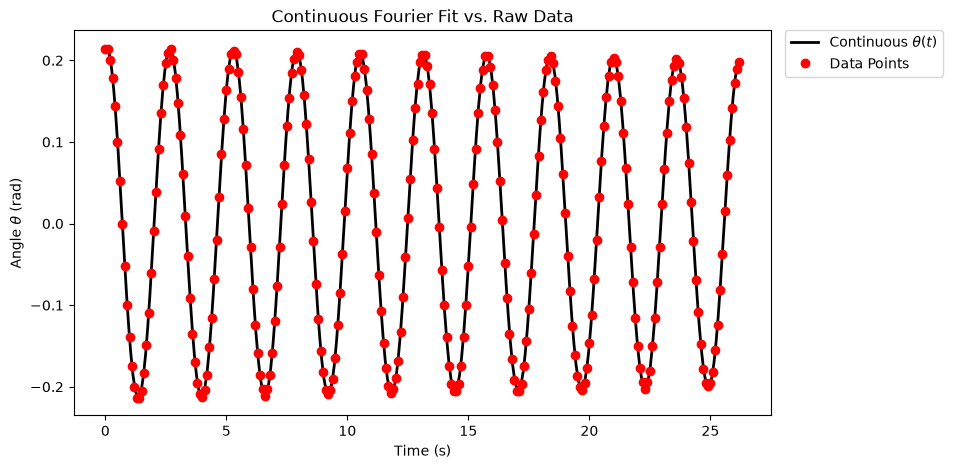

In [7]:
# plot Fourier Series Solution

t_plot = jnp.linspace(t_data[0], t_data[-1], 300)
theta_plot = jax.vmap(theta_func)(t_plot)

plt.figure(figsize=(9, 5), dpi=100)
plt.plot(t_plot, theta_plot, label='Continuous $\\theta(t)$', color='black', linewidth=2)
plt.plot(t_data, theta_data, 'ro', label='Data Points')
plt.xlabel('Time (s)')
plt.ylabel('Angle $\\theta$ (rad)')
plt.title('Continuous Fourier Fit vs. Raw Data')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.show()

In [8]:
@jax.jit # for fast computation of jax.grad(jax.grad())
def get_derivatives(t):

    dtheta_dt = jax.vmap(jax.grad(theta_func))(t)
    d2theta_dt2 = jax.vmap(jax.grad(jax.grad(theta_func)))(t)

    return dtheta_dt, d2theta_dt2

theta_dot, theta_ddot = get_derivatives(t_data)

In [9]:
# linear regression againts pendulum model: Xa = Y
# physics model: x'' = -a1 * x' - a2 * sin(x), x = theta
Y = theta_ddot
X = jnp.column_stack([-theta_dot, -jnp.sin(theta_data)])

a = jnp.linalg.solve(X.T @ X, X.T @ Y)
a1 = float(a[0])
a2 = float(a[1])

#Residual calculations
#Predicted angular acceleration
Y_pred = X @ a
#Residuals
residuals = Y - Y_pred

# a1 = c / m*L^2, a2 = g/L
g = 9.81 # m / s^2
L_data = 1.615 # m
m_data = 1 # kg

L_model = g / a2
L_err = jnp.abs(L_model - L_data) * 100
C_model = a1 * m_data * (L_model**2)

print(f'L_model: {L_model:.3f} m')
print(f'L_model error: {float(L_err):.3f} cm')
# print(f'a1: {a1:.3f}')
print(f'Air-Resistance Coef (C): {C_model:.3f}')

L_model: 1.693 m
L_model error: 7.829 cm
Air-Resistance Coef (C): 0.016


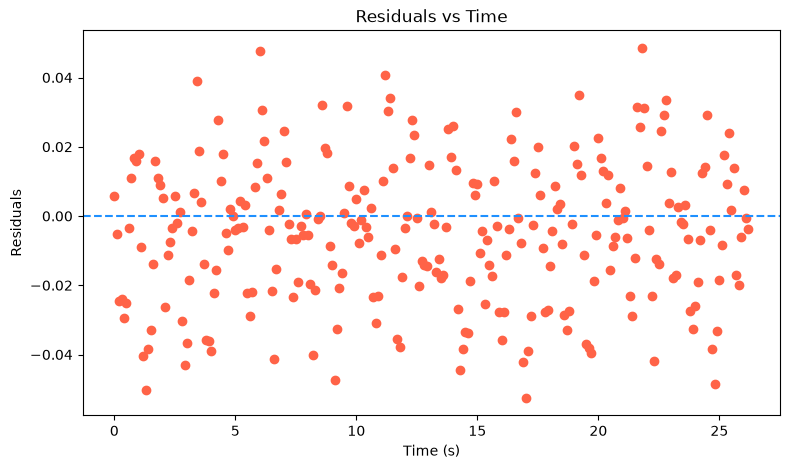

R^2 is found to be: 0.999.


In [10]:
#More residual calculations, to calculate R^2.
mse_physics = jnp.mean(residuals**2)
ss_res = jnp.sum(residuals**2)
ss_tot = jnp.sum((Y - jnp.mean(Y))**2)
r_squared = 1 - (ss_res / ss_tot)

#Residual plot
plt.figure(figsize=(9, 5), dpi=100)
plt.scatter(t_data, residuals, color = "tomato")
plt.axhline(y=0, color = "dodgerblue", linestyle = "dashed")
plt.xlabel('Time (s)')
plt.ylabel('Residuals')
plt.title('Residuals vs Time')
plt.show()

print(f"R^2 is found to be: {r_squared:.3f}.")

Applying the same analysis as with the curve fit method from the proof of concept, we can determine how the two parameters here are correlated, their sensitivity, and an error surface map.

In [11]:

# Residual variance sigma^2 = RSS / (N - p)
dof = len(Y) - 2
sigma2 = float(jnp.sum(residuals**2) / dof)

# Parameter covariance matrix: Cov(a) = sigma^2 * (X^T X)^(-1)
cov_matrix = np.array(jnp.linalg.inv(X.T @ X)) * sigma2
a1_std = float(np.sqrt(cov_matrix[0, 0]))
a2_std = float(np.sqrt(cov_matrix[1, 1]))

# Correlation coefficient rho between damping (a1) and restoring (a2)
rho = float(cov_matrix[0, 1] / (a1_std * a2_std))

# Regressor overlap / cosine similarity: dot(X1, X2) / (||X1|| * ||X2||)
dot_prod = float(jnp.dot(X[:, 0], X[:, 1]))
norm_x1 = float(jnp.linalg.norm(X[:, 0]))
norm_x2 = float(jnp.linalg.norm(X[:, 1]))
overlap = abs(dot_prod) / (norm_x1 * norm_x2)

print("--- Parameter Coupling Diagnostics ---")
print(f"Parameter Correlation |rho|: {abs(rho):.4f}")
print(f"Regressor Overlap Index:    {overlap:.4f} (Near-zero indicates orthogonal regressors)")
print(f"Damping parameter a1:       {a1:.5f} ± {a1_std:.5f} s^-1")
print(f"Restoring parameter a2:     {a2:.5f} ± {a2_std:.5f} s^-2")

--- Parameter Coupling Diagnostics ---
Parameter Correlation |rho|: 0.0013
Regressor Overlap Index:    0.0013 (Near-zero indicates orthogonal regressors)
Damping parameter a1:       0.00552 ± 0.00372 s^-1
Restoring parameter a2:     5.79346 ± 0.00893 s^-2


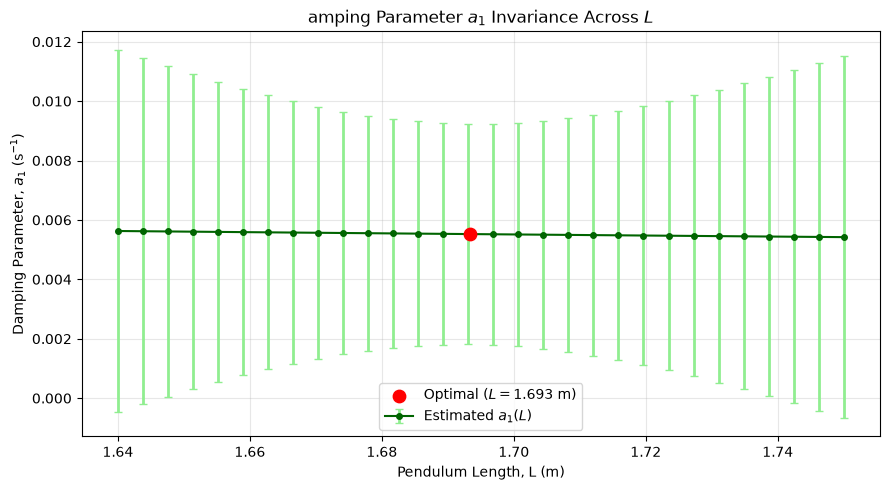

In [12]:

L_values = np.linspace(1.64, 1.75, 30)
C_values = []
C_errors = []

for L_val in L_values:
    # Fix a2 = g / L and subtract its contribution from angular acceleration Y
    a2_fixed = g / L_val
    Y_fixed = Y - (-a2_fixed * jnp.sin(theta_data))
    X1 = -theta_dot

    # 1-parameter normal equation: a1 = (X1^T Y_fixed) / (X1^T X1)
    a1_opt = float(jnp.dot(X1, Y_fixed) / jnp.dot(X1, X1))
    
    # Standard error of a1
    res_fixed = Y_fixed - a1_opt * X1
    se_a1 = float(jnp.sqrt(jnp.sum(res_fixed**2) / (len(Y_fixed) - 1) / jnp.dot(X1, X1)))
    
    C_values.append(a1_opt * m_data * L_val**2)
    C_errors.append(se_a1 * m_data * L_val**2)

C_values = np.array(C_values)
C_errors = np.array(C_errors)

# Plotting the correlation curve
plt.close('all')
plt.figure(figsize=(9, 5), dpi=100)

plt.errorbar(
    L_values,
    C_values,
    yerr=C_errors,
    fmt='-o',
    color='darkgreen',
    ecolor='lightgreen',
    elinewidth=2,
    capsize=3,
    markersize=4,
    label=r'Estimated $C(L)$',
)

# Highlight optimal estimated L
plt.scatter(L_model, C_model, color='red', s=80, zorder=5, label=f'Optimal ($L = {L_model:.3f}$ m)')

plt.xlabel('Pendulum Length, L (m)')
plt.ylabel(r'Air-resistance coefficient, $C$')
plt.title(r'Air-resistance coefficient $C$ Across $L$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Grid Minimum -> a1: 0.00556 s^-1, L: 1.69333 m (Min RSS: 0.1178)


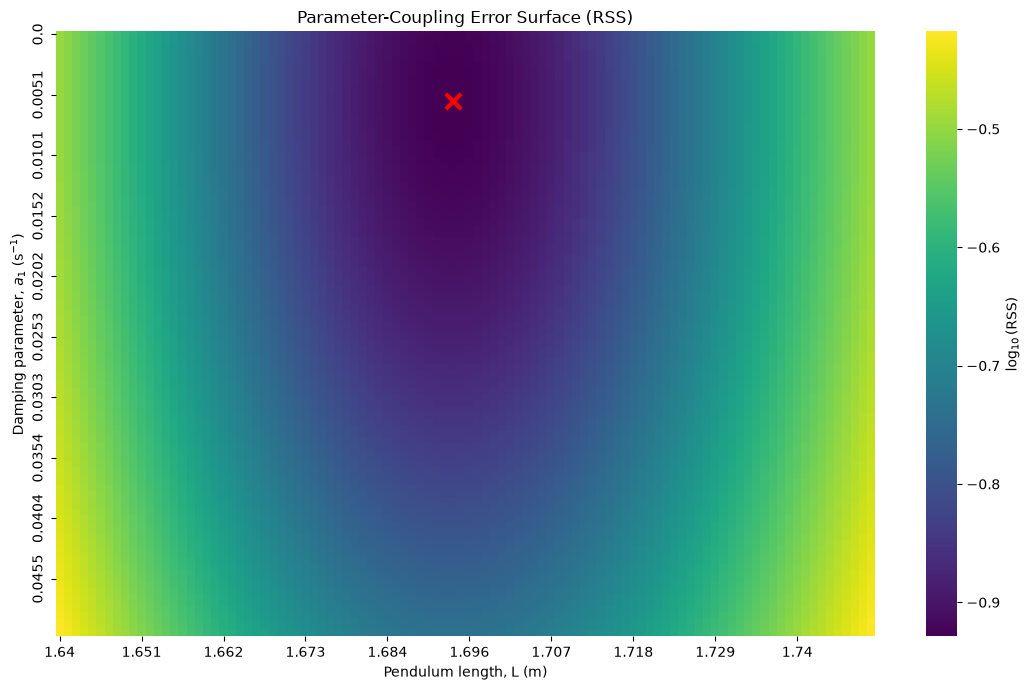

In [13]:

# Grid ranges around the optimal values
C_grid = np.linspace(0.00, 0.15, 100)
L_grid = np.linspace(1.64, 1.75, 100)

# Store Residual Sum of Squares (RSS) for every (C, L) pair
rss_matrix = np.empty((len(C_grid), len(L_grid)))

for i, C_val in enumerate(C_grid):
    for j, L_val in enumerate(L_grid):
        a2_val = g / L_val
        a1_val = C_val / (m_data * L_val**2)
        pred = -a1_val * theta_dot - a2_val * jnp.sin(theta_data)
        rss_matrix[i, j] = float(jnp.sum((Y - pred)**2))

# Convert to DataFrame for seaborn
error_surface = pd.DataFrame(
    rss_matrix,
    index=np.round(C_grid, 4),
    columns=np.round(L_grid, 3),
)

# Log10 scale to visualize the loss landscape
log_error_surface = np.log10(error_surface)

# Locate minimum
best_index = np.unravel_index(np.argmin(rss_matrix), rss_matrix.shape)
best_C = C_grid[best_index[0]]
best_L = L_grid[best_index[1]]
best_rss = rss_matrix[best_index]

print(f"Grid Minimum -> C: {best_C:.5f}, L: {best_L:.5f} m (Min RSS: {best_rss:.4f})")

# Plot Heatmap matching PoC styling
plt.figure(figsize=(11, 7), dpi=100)
ax = sns.heatmap(
    log_error_surface,
    cmap="viridis",
    cbar_kws={"label": r"$\log_{10}(\mathrm{RSS})$"},
    xticklabels=10,
    yticklabels=10,
)

# Mark the best-fit location
best_row = best_index[0] + 0.5
best_col = best_index[1] + 0.5
ax.scatter(best_col, best_row, color="red", marker="x", s=120, linewidths=3, label="Optimal")

ax.set_xlabel("Pendulum length, L (m)")
ax.set_ylabel(r"Air-resistance coefficient, $C$")
ax.set_title("Parameter-Coupling Error Surface (RSS)")
plt.tight_layout()
plt.show()

# How has the project progressed since the Proof of Concept?

The title of the project has shifted slightly to more accurately fit what the team is doing. Besides that, instead of using curvefit and solve_ivp, the team has shifted to using Linear regression to limit the reliance on initial guesses, as discussed above in the Methods section. Like the Proof of Concept code, the code starts by loading in a random subset of the Pendulum.xlsx data and identifying the time subset. The code then differs from the Proof of Concept, as it no longer uses solve_ivp. It instead sets up a "series" function which calculates the $a_x$, where x is either 1 or 2, λ (which is the decay constant), the frequency, and K which is the total number of sines/cosines in the Taylor series. Theta (the angle) was then calculated using these values and plotted against the raw data to show its fit to the model. Theta was then used in the "JAX" library to find its derivative and second derivative. Using that, $a_x$, where x is either 1 or 2, is calculated. Using $a_2$, the predicted L is calculated and using $a_1$ the air resistance coefficient is calculated. The residuals for "Y" (the angular acceleration) are also calculated and plotted, to show the fit of linear regression.

# Statements of contribution

Angela DiAndreth:

Sergey Dutt:

Edward Lombo-Becerra: